<a href="https://colab.research.google.com/github/jesusdelgadillo90/ab-testing-landing-page-experiment/blob/main/S9_Version_Student_Proyecto_Landing_Experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [ ]:
# importar librerías

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, levene, ttest_ind
from statsmodels.stats.proportion import proportions_ztest


In [ ]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [ ]:
# mostrar las primeras 5 filas
display(df.head())

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [ ]:
# información general
print('Filas y Columnas:', df.shape)
print("\nColumnas:")
print(df.columns)

print("\nTipos de datos:")
display(df.dtypes)

Filas y Columnas: (40000, 9)

Columnas:
Index(['user_id', 'date', 'landing', 'region', 'dispositivo', 'traffic_source',
       'user_type', 'converted', 'gasto'],
      dtype='object')

Tipos de datos:


user_id            object
date               object
landing            object
region             object
dispositivo        object
traffic_source     object
user_type          object
converted           int64
gasto             float64
dtype: object

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB



-**Valores Nulos** Este dataset cuenta con 40.000 registros y 9 columnas. No existen valores ausentes o nulos en ninguna de las variables.

-**Ajuste en el tipo de los datos** La columna `date` se cargó como tipo **object** y requiere convertirse a **datetime** usando la función (pd.to_datetime(df['date']))

-**Variables numéricas y binarias** `converted`está definida correctamente como entero, donde el **1** representa conversión y **0** no conversión. `gasto`es una variable numérica continua.

-**Variables categóricas** Las variables `user_id`, `landing`, `region`, `dispositivo`, `traffic_source`y `user_type`presententan tipos de datos consistentes **object**.


**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [ ]:
duplicated_users = df.duplicated(subset=['user_id']).sum()
print('Usuarios duplicados:', duplicated_users)

Usuarios duplicados: 0


 **Variable `date`**  
Explorar rango de fechas

In [ ]:
# Convertir la columna date de formato object a formato datetime

df['date'] = pd.to_datetime(df['date'], errors = "coerce")

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   user_id         40000 non-null  object        
 1   date            40000 non-null  datetime64[ns]
 2   landing         40000 non-null  object        
 3   region          40000 non-null  object        
 4   dispositivo     40000 non-null  object        
 5   traffic_source  40000 non-null  object        
 6   user_type       40000 non-null  object        
 7   converted       40000 non-null  int64         
 8   gasto           40000 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(6)
memory usage: 2.7+ MB


In [ ]:

# Resumen estadístico

display(df['date'].describe())


count                   40000
unique                     28
top       2026-01-24 00:00:00
freq                     1512
first     2026-01-01 00:00:00
last      2026-01-28 00:00:00
Name: date, dtype: object

In [ ]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01 00:00:00
Fecha máxima: 2026-01-28 00:00:00


**Variable `gasto` (numérica)**

In [ ]:
# Resumen estadístico
display(df['gasto'].describe())

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [ ]:
# Resumen estadístico de usuarios que se convirtieron
df[df['converted']== 1]['gasto'].describe()

count    5706.000000
mean       65.373668
std        30.896545
min        12.120000
25%        42.950000
50%        59.860000
75%        80.370000
max       303.680000
Name: gasto, dtype: float64

 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [ ]:
# Explorar variables categóricas y cómo se distribuyen

print("\nConteo de categorías:")
for col in ['landing', 'region', 'dispositivo', 'traffic_source', 'user_type']:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())
    print('-'*50)


Conteo de categorías:

--- landing ---
B    20018
A    19982
Name: landing, dtype: int64
--------------------------------------------------

--- region ---
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: region, dtype: int64
--------------------------------------------------

--- dispositivo ---
Mobile     24829
Desktop    15171
Name: dispositivo, dtype: int64
--------------------------------------------------

--- traffic_source ---
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64
--------------------------------------------------

--- user_type ---
Nuevo         26033
Recurrente    13967
Name: user_type, dtype: int64
--------------------------------------------------


- **Landing** Se valida que la muestra está correctamente balanceada entre la versión A y la versión B, sin anomalías en la asignación de usuarios.
- **Calidad de variables categóricas** No se observan errores tipográficos, registros duplicados con formato incorrecto ni valores inesperados o nulos en las columnas `region`, `dispositivo`, `traffic_source` y `user_type`.
- **Conclusión** Todas las columnas categóricas contienen los valores esperados para continuar con la etapa de pruebas estadísticas.

## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [ ]:
# Gasto por versión
gasto_A = df[(df['landing'] == 'A') & (df['converted'] == 1)]['gasto'] #completa el código
gasto_B = df[(df['landing'] == 'B') & (df['converted'] == 1)]['gasto'] #completa el código

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

### Prueba t de Student

**Hipótesis:**
- **Hipótesis nula (H₀):** No existe una diferencia significativa en el gasto promedio de los usuarios convertidos entre la página A y la página B.
- **Hipótesis alternativa (H₁):** Existe una diferencia significativa en el gasto promedio de los usuarios convertidos entre la página A y la página B.

In [ ]:
# Aplicar prueba

t_stat, p_value = ttest_ind(gasto_A, gasto_B)

# Visualizar resultados
print(f"Estadístico : {t_stat}")
print(f"Valor p: {p_value}")

Estadístico : -9.36563589591332
Valor p: 1.0635288333792346e-20


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula

**Interpretación de negocio:**  
Existe una diferencia estadísticamente significativa en el gasto promedio de los usuarios convertidos entre la página A y la página B. El valor del estadístico $t$ es negativo ($-9.36$), lo que indica que el gasto promedio de los usuarios convertidos en la página B es significativamente mayor que en la página A. En consecuencia, la versión B no solo atrae compradores, sino que logra que los clientes que convierten realicen compras de mayor valor monetario, aportando un mayor retorno económico por cliente.


---


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen difere]ncias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba Z-Test

**Hipótesis:**
- **Hipótesis nula (H₀):** La tasa de conversión es igual en ambas páginas. Cualquier diferencia se debe al azar del muestreo
- **Hipótesis alternativa (H₁):** La tasa de conversión es diferente entre las paginas A y B. Hay un factor que influye en la decisión de compra.

In [ ]:
# Número de usuarios convertidos por página

conversiones = df.groupby('landing')['converted'].sum()
print(conversiones)
print('-'*50)

# Total de usuarios por página

totales = df.groupby('landing')['converted'].count()
print(totales)
print('-'*50)

print("Usuarios convertidos por página:\n", conversiones)
print("\nTotal de usuarios por página:\n", totales)


landing
A    2512
B    3194
Name: converted, dtype: int64
--------------------------------------------------
landing
A    19982
B    20018
Name: converted, dtype: int64
--------------------------------------------------
Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [ ]:
# Organizar los datos en listas: con el número de exitos

exitos = [conversiones['A'], conversiones ['B']]
print(exitos)
print('-'*50)

# Organizar los datos en lista: con el total de observaciones por grupo

observaciones = [totales['A'], totales['B']]
print(observaciones)
print('-'*50)

[2512, 3194]
--------------------------------------------------
[19982, 20018]
--------------------------------------------------


In [ ]:
# Aplicar prueba

z_stat, p_value = proportions_ztest(exitos, observaciones)

# Visualizar resultados
print(f"Estadístico Z : {z_stat}")
print(f"Valor p: {p_value}")

# umbral de significancia
alpha = 0.05

if p_value < alpha:
    print('Rechazamos la hipótesis nula: Hay evidencia de una diferencia')
else:
    print('No rechazamos la hipótesis nula: No hay evidencia suficiente de una diferencia')

tasa_A = exitos[0] / observaciones[0]
tasa_B = exitos[1] / observaciones[1]

print(f"Tasa de conversion de la pagina A: {tasa_A: .2%}")
print(f"Tasa de conversion de la pagina B: {tasa_B: .2%}")

if tasa_A > tasa_B:
    print(f"\n La página A tiene una mayor tasa de conversión ({tasa_A - tasa_B: .2%}).")
elif tasa_B > tasa_A:
     print(f"\n La página B tiene una mayor tasa de conversión ({tasa_B - tasa_A: .2%}).")
else:
    print("\ Ambas páginas tienen la misma tasa de conversión")

Estadístico Z : -9.677362674655983
Valor p: 3.7629765627523803e-22
Rechazamos la hipótesis nula: Hay evidencia de una diferencia
Tasa de conversion de la pagina A:  12.57%
Tasa de conversion de la pagina B:  15.96%

 La página B tiene una mayor tasa de conversión ( 3.38%).


### 📝 Conclusión e interpretación

**Decisión:**  
Rechazamos la hipótesis nula: Hay evidencia de una diferencia.

**Interpretación de negocio:**  
Existe una diferencia estadísticamente significativa en la tasa de conversión entre la página A y la página B. La versión B genera una tasa de conversión sustancialmente mayor en comparación con la versión A (aproximadamente 15.95% vs 12.57%). Por lo tanto, la página B no solo logra que los usuarios gasten más promedio por compra, sino que también convence a una mayor proporción de visitantes para realizar una conversión.

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba Chi - Cuadrada (Chi2)

**Hipótesis:**


- **Hipótesis nula (H₀):** No existe relación entre las dos variables (son independientes), la conversión es independiente de la fuente de tráfico.
- **Hipótesis alternativa (H₁):** Existe una relación entre las dos variables (no son independientes), La conversión depende de la fuente de tráfico.



In [ ]:
# Observamos cuantos compraron y cuantos no
df['converted'].value_counts()

# Agregamos traffic_source a la linea
df[['traffic_source', 'converted']].value_counts()


traffic_source  converted
Organic         0            15507
Ads             0            10176
Email           0             5205
Referral        0             3406
Organic         1             2480
Ads             1             1759
Email           1              918
Referral        1              549
dtype: int64

In [ ]:
# Tabla de contingencia entre fuente de tráfico y conversión
tabla_trafico = pd.crosstab(df['traffic_source'], df['converted'], margins=True)
display(tabla_trafico)

# Tasa de conversión por cada fuente de tráfico
tasa_trafico = df.groupby('traffic_source')['converted'].mean().sort_values(ascending=False)
print("Tasa de conversión por fuente de tráfico:")
print(tasa_trafico.apply(lambda x: f"{x:.2%}"))

converted,0,1,All
traffic_source,,,
Ads,10176,1759,11935
Email,5205,918,6123
Organic,15507,2480,17987
Referral,3406,549,3955
All,34294,5706,40000


Tasa de conversión por fuente de tráfico:
traffic_source
Email       14.99%
Ads         14.74%
Referral    13.88%
Organic     13.79%
Name: converted, dtype: object


In [ ]:
# Tabla
tabla = pd.crosstab(df['traffic_source'],df['converted'])
display(tabla)

converted,0,1
traffic_source,,
Ads,10176,1759
Email,5205,918
Organic,15507,2480
Referral,3406,549


In [ ]:
# Aplicar prueba

chi2_stat, p_value, dof, expected = chi2_contingency(tabla)

print (f"Estadístico Chi-cuadrado: {chi2_stat: .3f}" )
print(f"Valor p: {p_value:.3f} ")
print(f"Grados de Libertad: {dof}")
print("\n Frecuencias esperadas:")
print(expected)

print('-'*50)

alpha = 0.05

if p_value < alpha:
    print("Rechazamos la hipótesis nula: Hay evidencia de asociación entre las variables")
else:
    print("No rechazamos la hipótesus nula: No hay evidencia suficiente de asociaciónb entre las variables")

Estadístico Chi-cuadrado:  8.662
Valor p: 0.034 
Grados de Libertad: 3

 Frecuencias esperadas:
[[10232.47225  1702.52775]
 [ 5249.55405   873.44595]
 [15421.15445  2565.84555]
 [ 3390.81925   564.18075]]
--------------------------------------------------
Rechazamos la hipótesis nula: Hay evidencia de asociación entre las variables


### 📝 Conclusión e interpretación

**Decisión:**  
Rechazamos la hipótesis nula: Hay evidencia de asociación entre las variables

**Interpretación de negocio:**  
Existe una relación estadísticamente significativa entre la fuente de tráfico y la tasa de conversión. Sin embargo, desde una perspectiva práctica de negocio, las diferencias entre canales son mínimas: el rendimiento varía únicamente entre un 13.79% (Organic) y un 14.99% (Email), representando una brecha de apenas 1.2 puntos porcentuales.
Por lo tanto, aunque Email y Ads muestran una leve ventaja sobre Referral u Organic, la conversión es bastante homogénea entre las distintas fuentes. No se recomienda hacer reasignaciones drásticas de presupuesto basándose únicamente en esta diferencia, sino evaluar otros factores como el costo de adquisición de clientes (CAC) de cada canal.


## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba Chi - Cuadrada (Chi2)

**Hipótesis:**
- **Hipótesis nula (H₀):** No existe relación entre las dos variables (son independientes), la conversión es independiente al tipo de usuario.
- **Hipótesis alternativa (H₁):** Existe una relación entre las dos variables (no son independientes), La conversión depende al tipo de usuario.


In [ ]:
# Observamos cuantos compraron y cuantos no
df['converted'].value_counts()

# Agregamos user_type  a la linea
df[['user_type', 'converted']].value_counts()


user_type   converted
Nuevo       0            22295
Recurrente  0            11999
Nuevo       1             3738
Recurrente  1             1968
dtype: int64

In [ ]:
# Tabla de contingencia entre tipo de usuario y conversión
tabla_user_type = pd.crosstab(df['user_type'], df['converted'], margins=True)
display(tabla_user_type)

# Tasa de conversión por cada tipo de usuario
tasa_user_type = df.groupby('user_type')['converted'].mean().sort_values(ascending=False)
print("Tasa de conversión por tipo de usuario:")
print(tasa_user_type.apply(lambda x: f"{x:.2%}"))

converted,0,1,All
user_type,,,
Nuevo,22295,3738,26033
Recurrente,11999,1968,13967
All,34294,5706,40000


Tasa de conversión por tipo de usuario:
user_type
Nuevo         14.36%
Recurrente    14.09%
Name: converted, dtype: object


In [ ]:
# Tabla
tabla_user_type = pd.crosstab(df['user_type'],df['converted'])
display(tabla_user_type)

converted,0,1
user_type,,
Nuevo,22295,3738
Recurrente,11999,1968


In [ ]:
# Aplicar prueba

chi2_stat, p_value, dof, expected = chi2_contingency(tabla_user_type)

print (f"Estadístico Chi-cuadrado: {chi2_stat: .3f}" )
print(f"Valor p: {p_value:.3f} ")
print(f"Grados de Libertad: {dof}")
print("\n Frecuencias esperadas:")
print(expected)

print('-'*50)

alpha = 0.05

if p_value < alpha:
    print("Rechazamos la hipótesis nula: Hay evidencia de asociación entre las variables")
else:
    print("No rechazamos la hipótesus nula: No hay evidencia suficiente de asociación entre las variables")


Estadístico Chi-cuadrado:  0.513
Valor p: 0.474 
Grados de Libertad: 1

 Frecuencias esperadas:
[[22319.39255  3713.60745]
 [11974.60745  1992.39255]]
--------------------------------------------------
No rechazamos la hipótesus nula: No hay evidencia suficiente de asociación entre las variables


### 📝 Conclusión e interpretación

**Decisión:**  
No se rechaza la hipótesis nula, ya que el valor_p es de 0.474, superando de forma clara el nivel de significancia.

**Interpretación de negocio:**  
Interpretación de negocio:No existe una diferencia estadísticamente significativa ni relevante en la práctica entre ambos tipos de usuario. Las tasas de conversión reales son casi idénticas: 14.36% para usuarios Nuevos frente a 14.09% para usuarios Recurrentes (una diferencia de apenas $0.27$ puntos porcentuales).Esto demuestra que la probabilidad de conversión es independiente de si el usuario visita la plataforma por primera vez o si ya la conocía. En consecuencia, la landing page funciona con la misma eficacia para ambos perfiles, por lo que no se requiere diseñar experiencias o embudos de conversión diferenciados según el tipo de usuario.

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

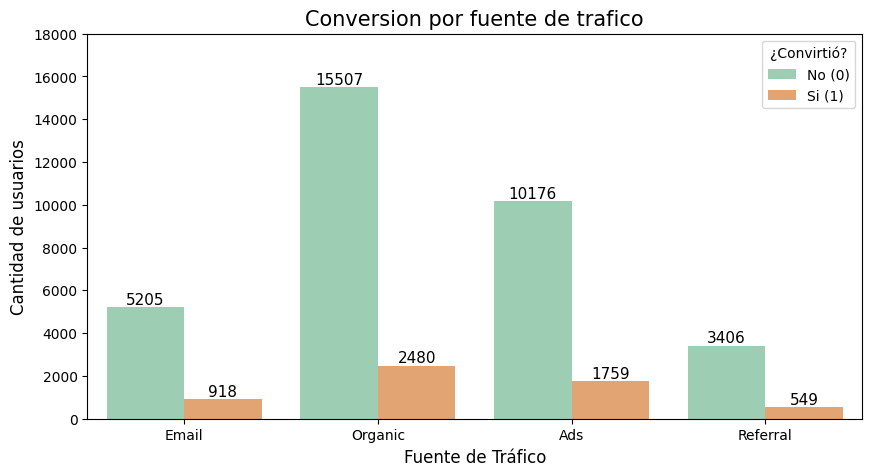

In [ ]:
table =pd.crosstab(df['traffic_source'], df['converted'])

plt.figure(figsize = (10, 5))
ax = sns.countplot(data = df, x = 'traffic_source', hue = 'converted', palette =['#95D5B2', '#F4A261'])

for bar in ax.patches:
    height = bar.get_height()
    ax.text(x = bar.get_x() + bar.get_width() / 2,
           y = height,
           s = height,
           ha = 'center',
           va = 'bottom',
           fontsize = 11)

plt.title('Conversion por fuente de trafico', fontsize = 15)
plt.xlabel('Fuente de Tráfico', fontsize = 12)
plt.ylabel('Cantidad de usuarios', fontsize = 12)
plt.ylim(0, 18000)
plt.legend (title = '¿Convirtió?', labels = ['No (0)', 'Si (1)'])
plt.show()

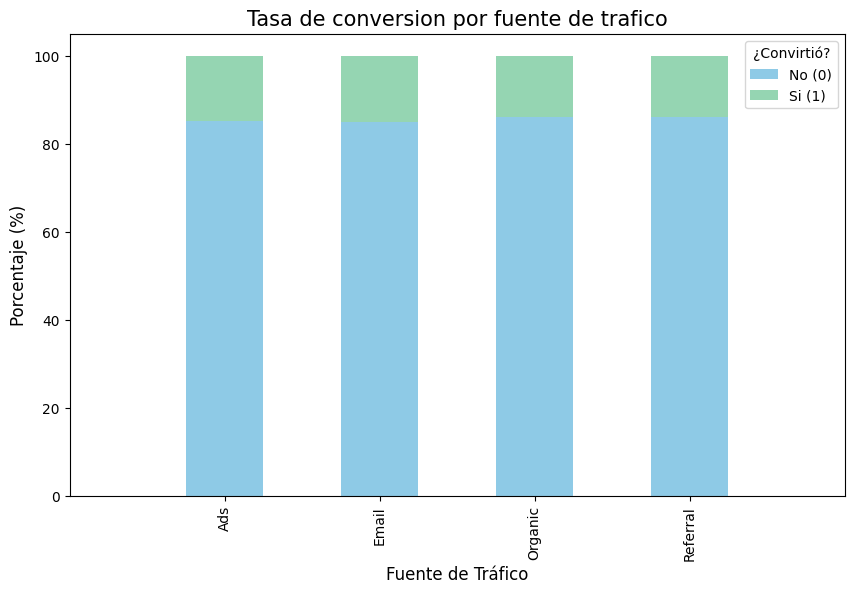

In [ ]:


table_1 = pd.crosstab(df['traffic_source'], df['converted'], normalize = 'index') * 100


ax = table_1.plot(kind = 'bar', stacked = True, figsize = (10, 6), color = ['#8ecae6', '#95d5b2'])

plt.title('Tasa de conversion por fuente de trafico', fontsize = 15)
plt.xlabel('Fuente de Tráfico', fontsize = 12)
plt.ylabel('Porcentaje (%)', fontsize = 12)
ax.set_xlim(-1, 4)
plt.legend (title = '¿Convirtió?', labels = ['No (0)', 'Si (1)'], loc = 'upper right')
plt.show()





**Análisis de la fuente de tráfico y la conversión:**

- **Volumen de usuarios:** La fuente Organic concentra la mayor cantidad de usuarios totales (17,987) y conversiones absolutas (2,480), seguida por Ads (11,935 usuarios). Referral es el canal con menor volumen (3,955 usuarios).
- **Tasa de conversión:** Los 4 canales muestran un rendimiento homogéneo con variaciones mínimas:
-Email: 14.99%
-Ads: 14.74%
-Referral: 13.88%
-Organic: 13.79%

- **Conclusión de negocio:**
Aunque la prueba Chi-cuadrado arrojó significancia estadística (p =0.034), la brecha de rendimiento entre el mejor canal (Email) y el de menor conversión (Organic) es de solo 1.2 puntos porcentuales. Esto confirma que no existe un canal masivamente superior, por lo que la inversión en marketing debe evaluarse considerando también el costo de adquisición de clientes de cada fuente de trafico.

### Relación entre el tipo de usuario y la conversión

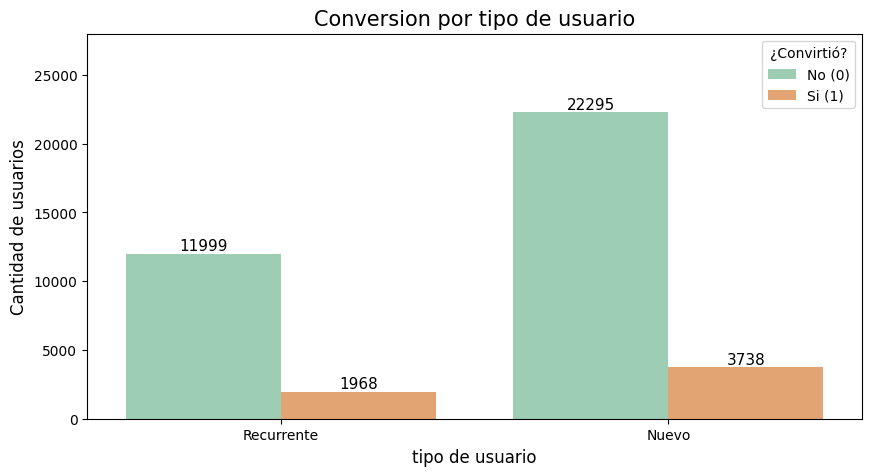

In [ ]:
plt.figure(figsize = (10, 5))
ax = sns.countplot(data = df, x = 'user_type', hue = 'converted', palette =['#95D5B2', '#F4A261'])

for bar in ax.patches:
    height = bar.get_height()
    ax.text(x = bar.get_x() + bar.get_width() / 2,
           y = height,
           s = height,
           ha = 'center',
           va = 'bottom',
           fontsize = 11)

plt.title('Conversion por tipo de usuario', fontsize = 15)
plt.xlabel('tipo de usuario', fontsize = 12)
plt.ylabel('Cantidad de usuarios', fontsize = 12)
plt.ylim(0, 28000)
plt.legend (title = '¿Convirtió?', labels = ['No (0)', 'Si (1)'])
plt.show()

In [ ]:
table_user_type =pd.crosstab(df['user_type'], df['converted'])

In [ ]:
table_user_type =pd.crosstab(df['user_type'], df['converted'], normalize = 'index') * 100


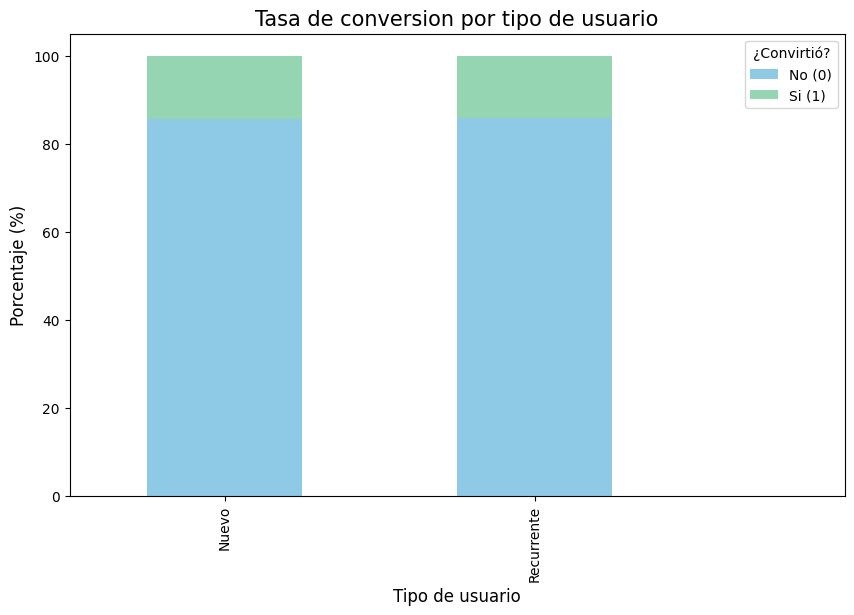

In [ ]:
ax = table_user_type.plot(kind = 'bar', stacked = True, figsize = (10, 6), color = ['#8ecae6', '#95d5b2'])

plt.title('Tasa de conversion por tipo de usuario', fontsize = 15)
plt.xlabel('Tipo de usuario', fontsize = 12)
plt.ylabel('Porcentaje (%)', fontsize = 12)
ax.set_xlim(-0.5, 2)
plt.legend (title = '¿Convirtió?', labels = ['No (0)', 'Si (1)'], loc = 'upper right')
plt.show()


**Análisis del tipo de usuario y la conversión:**

- **Volumen de usuarios:**  La plataforma registra un número significativamente mayor de usuarios Nuevos (26,033) en comparación con los usuarios Recurrentes (13,967), representando aproximadamente el 65% del tráfico total.
- **Tasa de conversión:** La efectividad entre ambos grupos es prácticamente idéntica:
Nuevos: 14.36%
Recurrentes: 14.09%

- **Conclusión de negocio:** El test Chi-cuadrado realizado en el Paso 5 confirmó que no existe una diferencia estadísticamente significativa entre ambos segmentos (p=0.474). En términos prácticos de negocio, la brecha es de apenas 0.27 puntos porcentuales. Esto demuestra que la landing page funciona con la misma eficacia para atraer a primeros visitantes que para convertir a usuarios habituales, por lo que no se requiere invertir recursos en desarrollar experiencias de conversión diferenciadas según el tipo de usuario.

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**
- Observacion 1: Los usuarios convertidos en la versión B generaron un gasto promedio mayor en comparación con los de la versión A.
- Observacion 2: La prueba $t$ de Student confirmó que esta diferencia es estadísticamente significativa ($t = -9.37$, $p = 1.06 \times 10^{-20}$).
- **Interpretación:** La landing page B no solo atrae compradores, sino que impulsa pedidos de mayor valor monetario por transacción.

<br>

**Tasa de conversión:**
- Observacion 1: La tasa de conversión de la página B ($15.96\%$) superó a la de la página A ($12.57\%$).
- Observacion 2 : La prueba $Z$ de proporciones / Chi-cuadrado confirmó significancia estadística ($p = 3.76 \times 10^{-22}$).
- **Interpretación:** La versión B es sustancialmente más efectiva para convertir visitantes en clientes activos.

---

#### 📊 **Segmentación por fuente de tráfico**
- Observación: Aunque existe una leve variación estadística entre canales ($p = 0.034$), la tasa de conversión oscila en un rango muy estrecho entre el $13.79\%$ (Organic) y el $14.99\%$ (Email).
- **Interpretación:**: Ningún canal es drásticamente superior en conversión. La asignación de presupuesto publicitario debe basarse en el Costo de Adquisición de Clientes (CAC) y el volumen de cada canal.

 ---

#### 📊 **Segmentación por tipo de usuario**
- Observacion : No se encontró diferencia estadísticamente significativa ($p = 0.474$), registrando $14.36\%$ en usuarios Nuevos y $14.09\%$ en Recurrentes.
- **Interpretación:** La nueva landing page funciona de manera consistente tanto para primeros visitantes como para clientes habituales.

---

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

---

#### 💡 **Recomendaciones de negocio:**
- Implementar la versión B de la landing page al 100% del tráfico. La página B supera a la A en ambas métricas principales: mayor tasa de conversión ($15.96\%$ vs $12.57\%$) y mayor gasto promedio por cliente convertido.
- Optimizar el presupuesto publicitario enfocándose en el retorno sobre la inversión (ROAS) de los canales con mayor volumen (Organic y Ads), sin necesidad de crear experiencias o embudos diferenciados según el tipo de usuario.